# Setup

In [1]:
# loading libraries for data manipulation
import numpy as np
import pandas as pd

# loading libraries for data visualization
import matplotlib.pyplot as plt
from plotnine import *
from PIL import Image

# import tensorflow and keras packages
import tensorflow as tf
from tensorflow import keras

# import kagglehub library to fetch data
import kagglehub

# import os and glob for file directory operations
import os,glob

# helper functions
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import warnings
warnings.filterwarnings('ignore')

In [2]:
%pip install kagglehub

# Load data

In [3]:
# pass dataset name as parameter
path = kagglehub.dataset_download("misrakahmed/vegetable-image-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'vegetable-image-dataset' dataset.
Path to dataset files: /kaggle/input/vegetable-image-dataset


In [4]:
# we can use the glob library to identify the file structure
pattern = f"{path}/**/*"

files = glob.glob(pattern, recursive=True)

# display folders
[i for i in files if os.path.isdir(i)]

['/kaggle/input/vegetable-image-dataset/Vegetable Images',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/test',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/train',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation/Broccoli',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation/Capsicum',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation/Bottle_Gourd',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation/Radish',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation/Tomato',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation/Brinjal',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation/Pumpkin',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation/Carrot',
 '/kaggle/input/vegetable-image-dataset/Vegetable Images/validation/Papaya',
 '/kaggle/input/vegetable-image-datas

In [5]:
# set training data path
train_path = path+"/Vegetable Images/train/"

# set validation and testing data paths
val_path = path+"/Vegetable Images/validation/"
test_path = path+"/Vegetable Images/test/"

print("Training folder exists:", os.path.isdir(train_path))
print("Validation folder exists:", os.path.isdir(val_path))
print("Testing folder exists:", os.path.isdir(test_path))

Training folder exists: True
Validation folder exists: True
Testing folder exists: True


In [6]:
# Load the dataset using Keras utility
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    label_mode=None,       # We only need the images for autoencoders, no labels
    color_mode='grayscale', # Matches model's (224, 224, 1) input shape
    image_size=(224, 224),
    batch_size=1000,       # Load up to 1000 images in one batch
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    label_mode=None,
    color_mode='grayscale',
    image_size=(224, 224),
    batch_size=200,        # Load up to 200 images in one batch
    shuffle=True
)

# Convert to numpy arrays and normalize pixel values to [0, 1]
X_train = next(iter(train_ds)).numpy() / 255.0
X_test = next(iter(test_ds)).numpy() / 255.0

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Found 15000 files.
Found 3000 files.
Train shape: (1000, 224, 224, 1)
Test shape: (200, 224, 224, 1)


# Denoising convolutional autoencoder

In [7]:
# add noise
noise_factor = 0.25
X_train_noisy = X_train + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=X_train.shape)
X_test_noisy = X_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=X_test.shape)
X_train_noisy = np.clip(X_train_noisy, 0., 1.)
X_test_noisy = np.clip(X_test_noisy, 0., 1.)

In [8]:
# define the denoising convolutional autoencoder
input_img = tf.keras.layers.Input(shape=(224,224,1))

# encoder
x = tf.keras.layers.Conv2D(64,(3,3),activation='relu',padding='same')(input_img)
x = tf.keras.layers.MaxPooling2D((2,2),padding='same')(x)
x = tf.keras.layers.Conv2D(32,(3,3),activation='relu',padding='same')(x)
encoded = tf.keras.layers.MaxPooling2D((2,2),padding='same')(x)

# decoder -- same thing but in reverse
x = tf.keras.layers.Conv2D(32,(3,3),activation='relu',padding='same')(encoded)
x = tf.keras.layers.UpSampling2D((2,2))(x)
x = tf.keras.layers.Conv2D(64,(3,3),activation='relu',padding='same')(x)
x = tf.keras.layers.UpSampling2D((2,2))(x)
decoded = tf.keras.layers.Conv2D(1,(3,3),activation='sigmoid',padding='same')(x)

# the entire model
denoising_c_autoencoder = tf.keras.Model(input_img,decoded)

In [9]:
# view the network architecture
denoising_c_autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 224, 224, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 1)    │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,425 (185.25 KB)

 Trainable params: 47,425 (185.25 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# compile model
denoising_c_autoencoder.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy')

# train model
denoising_c_autoencoder.fit(
    X_train_noisy, X_train,
    epochs=25,
    batch_size=128,
    shuffle=True,
    validation_data=(X_test_noisy, X_test),
    verbose=1
)

Epoch 1/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 796ms/step - loss: 0.7561 - val_loss: 0.6062
Epoch 2/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 451ms/step - loss: 0.6420 - val_loss: 0.6092
Epoch 3/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 445ms/step - loss: 0.6201 - val_loss: 0.6044
Epoch 4/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 447ms/step - loss: 0.6025 - val_loss: 0.5978
Epoch 5/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 460ms/step - loss: 0.5999 - val_loss: 0.5958
Epoch 6/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 452ms/step - loss: 0.5964 - val_loss: 0.5929
Epoch 7/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 454ms/step - loss: 0.5945 - val_loss: 0.5916
Epoch 8/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 456ms/step - loss: 0.5935 - val_loss: 0.5909
Epoch 9/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 467ms/step - loss: 0.5929 - val_loss: 0.5901
Epoch 10/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 463ms/step - loss: 0.5923 - val_loss: 0.5896
Epoch 11/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 463ms/step - loss: 0.5918 - val_loss: 0.5891
Epoch 12/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 469ms/step - loss: 0.5915 - val_lo

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


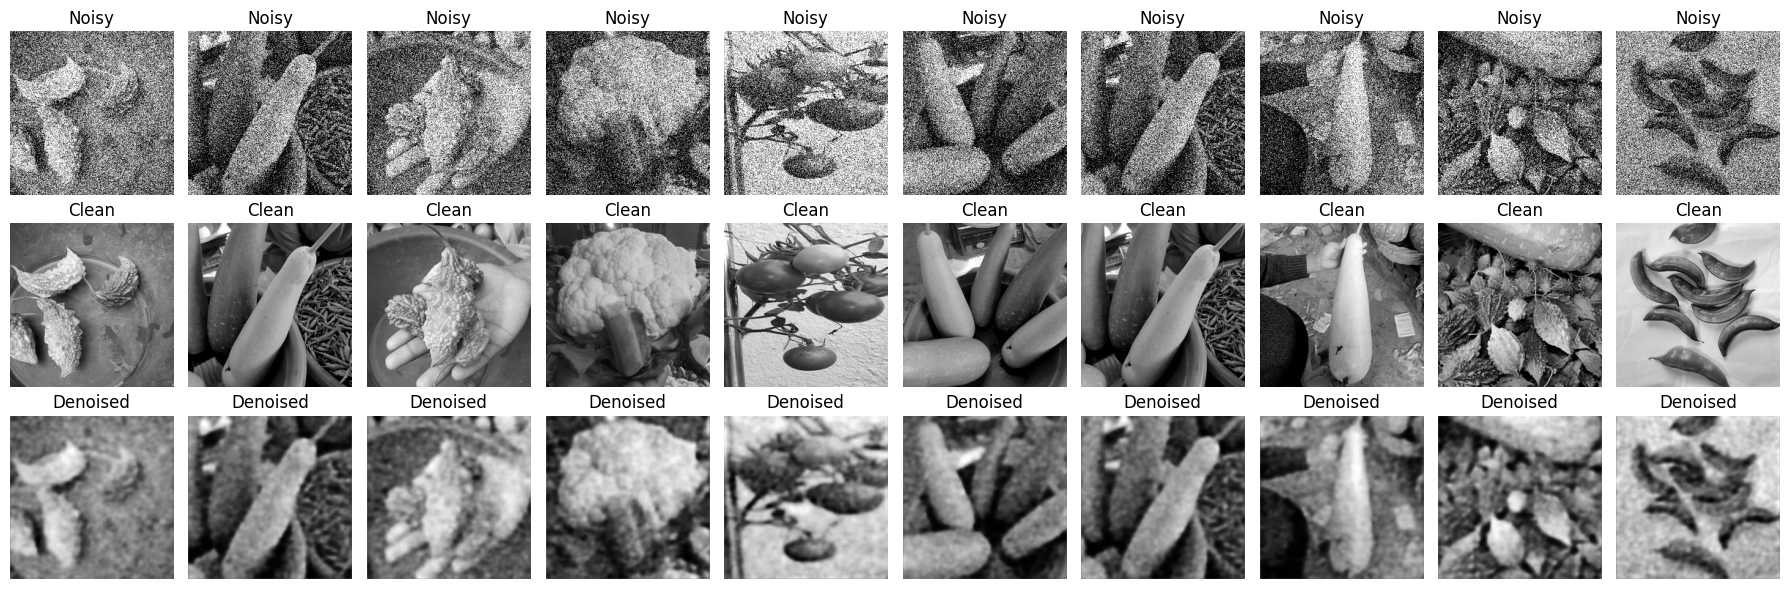

In [16]:
# predict using autoencoder
X_test_denoised = denoising_c_autoencoder.predict(X_test_noisy)

# visualization function
def plot_reconstructions(input,noisy_input,ae_output,n=10):
    plt.figure(figsize=(18, 6))
    for i in range(n):
        # Noisy input
        ax = plt.subplot(3, n, i + 1)
        plt.imshow(noisy_input[i].reshape(224, 224), cmap='gray')
        plt.title("Noisy")
        plt.axis('off')

        # Ground truth
        ax = plt.subplot(3, n, i + 1 + n)
        plt.imshow(input[i].reshape(224, 224), cmap='gray')
        plt.title("Clean")
        plt.axis('off')

        # Denoised output
        ax = plt.subplot(3, n, i + 1 + 2 * n)
        plt.imshow(ae_output[i].reshape(224, 224), cmap='gray')
        plt.title("Denoised")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_reconstructions(X_test,X_test_noisy,X_test_denoised,n=10)